# Fisher y bias con momentos: máxima entropía

Este cuaderno usa exclusivamente `nz_model="moments"` con los datos de
`source_year1_outliers_OFF.npz`. La distribución central es la media de
todas las realizaciones; `nz_truth` se reserva para comparar y predecir el bias.

La reconstrucción es
$n(z)=\exp[\lambda_0+\lambda_1z+\cdots+\lambda_Kz^K]$.
`nz_moments` obtiene los multiplicadores de Lagrange imponiendo los momentos.
Fisher varía desplazamientos de los **momentos**, no los multiplicadores.
El momento $m_0=1$ queda fijo: `[7, 8, 4, 4, 4]` significa
`[6, 7, 3, 3, 3]` parámetros libres por bin.

In [1]:
import os
# Evita multiplicar los hilos de BLAS/OpenMP al usar dos procesos de Fisher.
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

from pathlib import Path
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import tables_io
import fisherA2Z.fisher_flex as ff
from fisherA2Z import nz_moments as nzm

FisherFlex = ff.FisherFlex
plt.rcParams["figure.dpi"] = 110
%matplotlib inline

## Datos y configuración

Las rutas se obtienen del repositorio local instalado. `N_MOMENTS` incluye
la normalización; no lo confundas con el número de parámetros libres.

In [2]:
REPO = Path(ff.__file__).resolve().parents[2]
EXAMPLE_DIR = REPO / "examples" / "nzdc_example"
DATA_FILE = REPO.parent / "yaw_bins" / "Results" / "source_year1_outliers_OFF.npz"
BHAT_FILE = EXAMPLE_DIR / "nz_challenge_taskset_1_cardinal_1yr_bhat_wfd.hdf5"
OUTPUT_DIR = EXAMPLE_DIR / "outputs_moments_main"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

N_MOMENTS = [7, 8, 4, 4, 4]
SUBDIVISIONS = 32  # Malla fina para evaluar la PDF continua y los espectros.
FORECAST_PARAMS = dict(ell_min_cs=300, ell_max_cs=1800)
FISHER_FILE = OUTPUT_DIR / (
    f"fisher_{DATA_FILE.stem}_nm{'-'.join(map(str, N_MOMENTS))}.npz"
)

with np.load(DATA_FILE) as data:
    z_native = np.asarray(data["z_grid"], dtype=float)
    samples = np.asarray(data["samples"], dtype=float)
    nz_true_native = nzm.normalize_nz(z_native, data["nz_truth"])

n_bins, n_realizations, n_z = samples.shape  # (bins, realizaciones, redshift)
N_MOMENTS = nzm.moment_counts(N_MOMENTS, n_bins)
nz_central_native = nzm.normalize_nz(z_native, samples.mean(axis=1))
if nz_true_native.shape != nz_central_native.shape:
    raise ValueError("La distribución central y la verdad deben tener los mismos bins y malla.")

print("Datos:", DATA_FILE.name)
print("samples:", samples.shape)
print("Momentos totales por bin:", N_MOMENTS)
print("Parámetros libres por bin:", np.asarray(N_MOMENTS) - 1)

Datos: source_year1_outliers_OFF.npz
samples: (5, 199499, 40)
Momentos totales por bin: (7, 8, 4, 4, 4)
Parámetros libres por bin: [6 7 3 3 3]


## Prior de momentos

Para cada realización se mide $m_k=\int z^k n(z)\,dz$ sobre la PDF
normalizada y lineal entre los nodos originales. Se usa la covarianza de
esos momentos. Se conservan las correlaciones entre órdenes dentro de cada bin;
este prior no incluye correlaciones entre bins.

In [3]:
photoz_prior_cov = []
moments_fid = []
for b, count in enumerate(N_MOMENTS):
    fid = nzm.raw_moments(z_native, nz_central_native[b], count)
    measured = nzm.raw_moments(z_native, samples[b], count)[:, 1:]  # Excluye m0 fijo.
    covariance = np.cov(measured, rowvar=False, ddof=1)
    photoz_prior_cov.append(covariance)
    moments_fid.append(fid)
    offset = (measured.mean(axis=0) - fid[1:]) / np.sqrt(np.diag(covariance))
    print(f"Bin {b+1}: prior {covariance.shape}, máximo |media-fiducial|/sigma = {np.max(np.abs(offset)):.3g}")

photoz_prior_cov = nzm.validate_prior_cov(photoz_prior_cov, N_MOMENTS)
#del samples, measured  # Ya tenemos el prior; no hace falta reconstruir cada realización.

Bin 1: prior (6, 6), máximo |media-fiducial|/sigma = 0.0254
Bin 2: prior (7, 7), máximo |media-fiducial|/sigma = 0.025
Bin 3: prior (3, 3), máximo |media-fiducial|/sigma = 0.0235
Bin 4: prior (3, 3), máximo |media-fiducial|/sigma = 0.103
Bin 5: prior (3, 3), máximo |media-fiducial|/sigma = 0.00784


## Densidad efectiva por bin

Se conserva la conversión Cardinal 1yr de las libretas de referencia.
`neff` es una entrada del sondeo en galaxias/arcmin²: no se obtiene de
las PDFs normalizadas del NPZ. Para otro catálogo, deben usarse sus
densidades y asignaciones tomográficas correspondientes.

In [4]:
N_CATALOG = 3_505_864  # Objetos de Cardinal 1yr en el área de la simulación.
N_SAMPLED = 1_000_000
AREA_ARCMIN2 = 107.4295 * 3600

bhat_table = tables_io.read(str(BHAT_FILE))
counts = np.bincount(bhat_table["bhat_for_wide_data"], minlength=n_bins)[:n_bins]
neff = counts * (N_CATALOG / AREA_ARCMIN2) / N_SAMPLED
print("Conteos por bin:", counts)
print("neff [gal/arcmin²]:", neff)

Conteos por bin: [196661 196375 189284 214686 202994]
neff [gal/arcmin²]: [1.7827369  1.7801443  1.71586421 1.94613397 1.8401457 ]


## Reconstrucción de máxima entropía y modelo Fisher

Solo se interpolan la central y la verdad a una malla fina. La interpolación
lineal conserva los momentos de entrada, por lo que el prior medido arriba
sigue siendo válido. Se pasa mediante `photoz_prior_cov`; no hace falta
interpolar ni mantener en memoria el ensemble completo.

z_grid = np.unique(np.concatenate([
    np.linspace(a, b, SUBDIVISIONS + 1)
    for a, b in zip(z_native[:-1], z_native[1:])
]))
nz_central = np.array([np.interp(z_grid, z_native, row) for row in nz_central_native])
nz_true = np.array([np.interp(z_grid, z_native, row) for row in nz_true_native])

# Comprueba que el refinamiento no cambie los momentos que definen el prior.
for b, count in enumerate(N_MOMENTS):
    np.testing.assert_allclose(
        nzm.raw_moments(z_grid, nz_central[b], count), moments_fid[b],
        rtol=1e-11, atol=1e-12,
    )

flex = FisherFlex(
    nz_source=nz_central,
    z_grid=z_grid,
    nz_realizations=samples,            
    photoz_prior_cov=None,
    neff_source=neff,
    fsky=0.5,
    sigma_e=0.26,
    mode="cosmic_shear",
    nz_model="moments",
    n_moments=N_MOMENTS,
    prior_mode="full",
    deriv_method="central",
)
nz_maxent = flex.nz_source_fid  # Esta es la n(z) fiducial que realmente usa Fisher.
print("Malla de Fisher:", z_grid.size, "nodos")
print("Parámetros libres de momentos:", sum(p.startswith("mshift") for p in flex.param_order))

In [5]:
# Todas las PDFs utilizan la misma malla original.
z_grid = z_native.copy()
nz_central = nz_central_native.copy()
nz_true = nz_true_native.copy()

assert samples.shape[-1] == z_grid.size

flex = FisherFlex(
    nz_source=nz_central,
    z_grid=z_grid,
    nz_realizations=samples,
    realizations_axis=1,       # samples: (bins, realizaciones, redshift)
    photoz_prior_cov=None,     # Fisher calculará el prior desde samples
    neff_source=neff,
    fsky=0.5,
    sigma_e=0.26,
    mode="cosmic_shear",
    nz_model="moments",
    n_moments=N_MOMENTS,
    prior_mode="full",
    deriv_method="central",
)

nz_maxent = flex.nz_source_fid

print("Malla de Fisher:", z_grid.size, "nodos")
print("Bloques del prior:", [c.shape for c in flex.pz_prior_cov])

Malla de Fisher: 40 nodos
Bloques del prior: [(6, 6), (7, 7), (3, 3), (3, 3), (3, 3)]


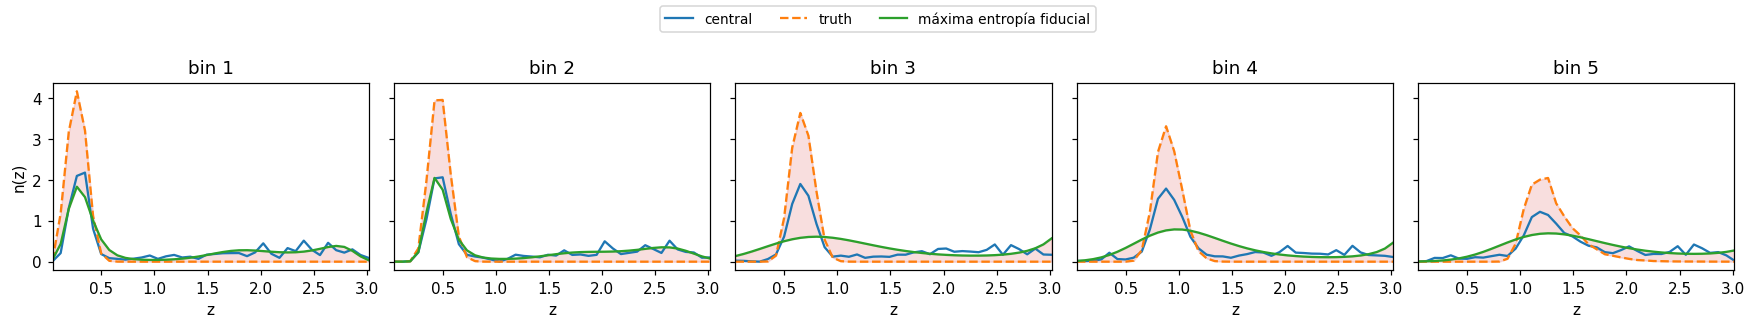

In [6]:
fig, axes = plt.subplots(1, n_bins, figsize=(16, 3), sharey=True, squeeze=False)
for b, ax in enumerate(axes[0]):
    ax.plot(z_grid, nz_central[b], color="C0", label="central" if b == 0 else None)
    ax.plot(z_grid, nz_true[b], "--", color="C1", label="truth" if b == 0 else None)
    ax.plot(z_grid, nz_maxent[b], color="C2", label="máxima entropía fiducial" if b == 0 else None)
    ax.fill_between(z_grid, nz_maxent[b], nz_true[b], color="C3", alpha=0.15)
    ax.set(title=f"bin {b+1}", xlabel="z", xlim=(z_grid[0], z_grid[-1]))
axes[0, 0].set_ylabel("n(z)")
fig.legend(loc="upper center", ncol=3, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.savefig(OUTPUT_DIR / "nz_moments.png", dpi=160, bbox_inches="tight")
plt.show()

## Forecast: primero compute, después forecast

`FisherFlex(...)` prepara el modelo y el prior. **`compute()` calcula los
espectros, sus derivadas y la covarianza de los observables**; `forecast()`
construye la matriz Fisher con los cortes de escala y marginaliza los
parámetros libres, incluidos los momentos. Cambiar de modelo requiere
calcular de nuevo las derivadas; no se reutilizan archivos de otro modelo.

In [7]:
flex.compute(parallel=True, n_proc=2, save=str(FISHER_FILE))
res = flex.forecast(**FORECAST_PARAMS)

s8, s8_err = res.s8()
print(f"Cosmic shear, momentos: S_8 = {s8:.4f} +/- {s8_err:.4f}")
print(f"FoM(w0,wa) = {res.fom('w_0', 'w_a'):.2f}")
print("Resultados guardados en:", FISHER_FILE)

Computing the fiducial data vector and covariance ...
Computing derivatives for 43 parameters (parallel) ...
Done.
Saved to /home/davidmarquez/photometric_redshifts_project/fisherA2Z/examples/nzdc_example/outputs_moments_main/fisher_source_year1_outliers_OFF_nm7-8-4-4-4.npz
Cosmic shear, momentos: S_8 = 0.8523 +/- 0.0183
FoM(w0,wa) = 3.34
Resultados guardados en: /home/davidmarquez/photometric_redshifts_project/fisherA2Z/examples/nzdc_example/outputs_moments_main/fisher_source_year1_outliers_OFF_nm7-8-4-4-4.npz


## Predicted bias

Se compara la verdad con la reconstrucción fiducial de máxima entropía,
usando los mismos cortes y priors del forecast:
$\Delta\theta = F^{-1} J^T\,\mathrm{Cov}^{-1}(C^{\rm truth}-C^{\rm fid})$.
Por ello, el bias incluye también el efecto de que un número finito de
momentos no reproduzca exactamente la distribución central.

Es una predicción lineal de Fisher. `mafe()` resume el residuo fraccional
de los espectros; un residuo grande limita la interpretación cuantitativa.

**Si el residuo es de decenas de por ciento, las flechas describen una extrapolación lineal: no deben interpretarse como una predicción precisa del sesgo de un ajuste completo.**

In [8]:
bias = flex.forecast_bias(nz_truth=nz_true, forecast_params=FORECAST_PARAMS)
COSMO_PARAMS = ["omega_m", "sigma_8", "w_0", "w_a"]
print(bias.summary(COSMO_PARAMS))

s8_fid, s8_shifted, ds8, ds8_sigma = bias.s8()
print(f"\nS_8: {s8_fid:.4f} -> {s8_shifted:.4f} ({ds8:+.4f}, {ds8_sigma:+.2f} sigma)")
print(f"Residuo fraccional medio de los espectros (MAFE): {bias.mafe():.2%}")

parameter         fiducial        bias  bias/sigma     shifted
omega_m             0.3156    0.086014       2.675     0.40161
sigma_8              0.831    -0.13136      -3.850     0.69964
w_0                     -1    -0.87997      -2.438       -1.88
w_a                      0       5.896       5.231       5.896

S_8: 0.8523 -> 0.8095 (-0.0428, -2.34 sigma)
Residuo fraccional medio de los espectros (MAFE): 53.65%


## Bias en dos dimensiones

`bias/sigma` es una comparación marginal por parámetro. `bias_2d`
utiliza la covarianza conjunta del par, marginalizando los demás.

In [9]:
PARAMETER_PAIRS = [("omega_m", "sigma_8"), ("w_0", "w_a")]
for pair in PARAMETER_PAIRS:
    print(bias.bias_2d(*pair))
    print()

bias in the (omega_m, sigma_8) plane
  omega_m           0.3156 ->     0.40161   (+2.67 sigma_1D)
  sigma_8            0.831 ->     0.69964   (-3.85 sigma_1D)
  joint: chi2 = 19.104, sqrt(chi2) = 4.37, enclosing 100.0% of the posterior
  direction: -56.8 deg;  inside 1 sigma: False;  inside 2 sigma: False

bias in the (w_0, w_a) plane
  w_0                   -1 ->       -1.88   (-2.44 sigma_1D)
  w_a                    0 ->       5.896   (+5.23 sigma_1D)
  joint: chi2 = 29.631, sqrt(chi2) = 5.44, enclosing 100.0% of the posterior
  direction: +98.5 deg;  inside 1 sigma: False;  inside 2 sigma: False



## Corner + arrows

Azul: forecast fiducial. Naranja: desplazamiento predicho y contorno
trasladado. El contorno naranja conserva la covarianza fiducial;
no es un nuevo ajuste calculado en el punto desplazado.

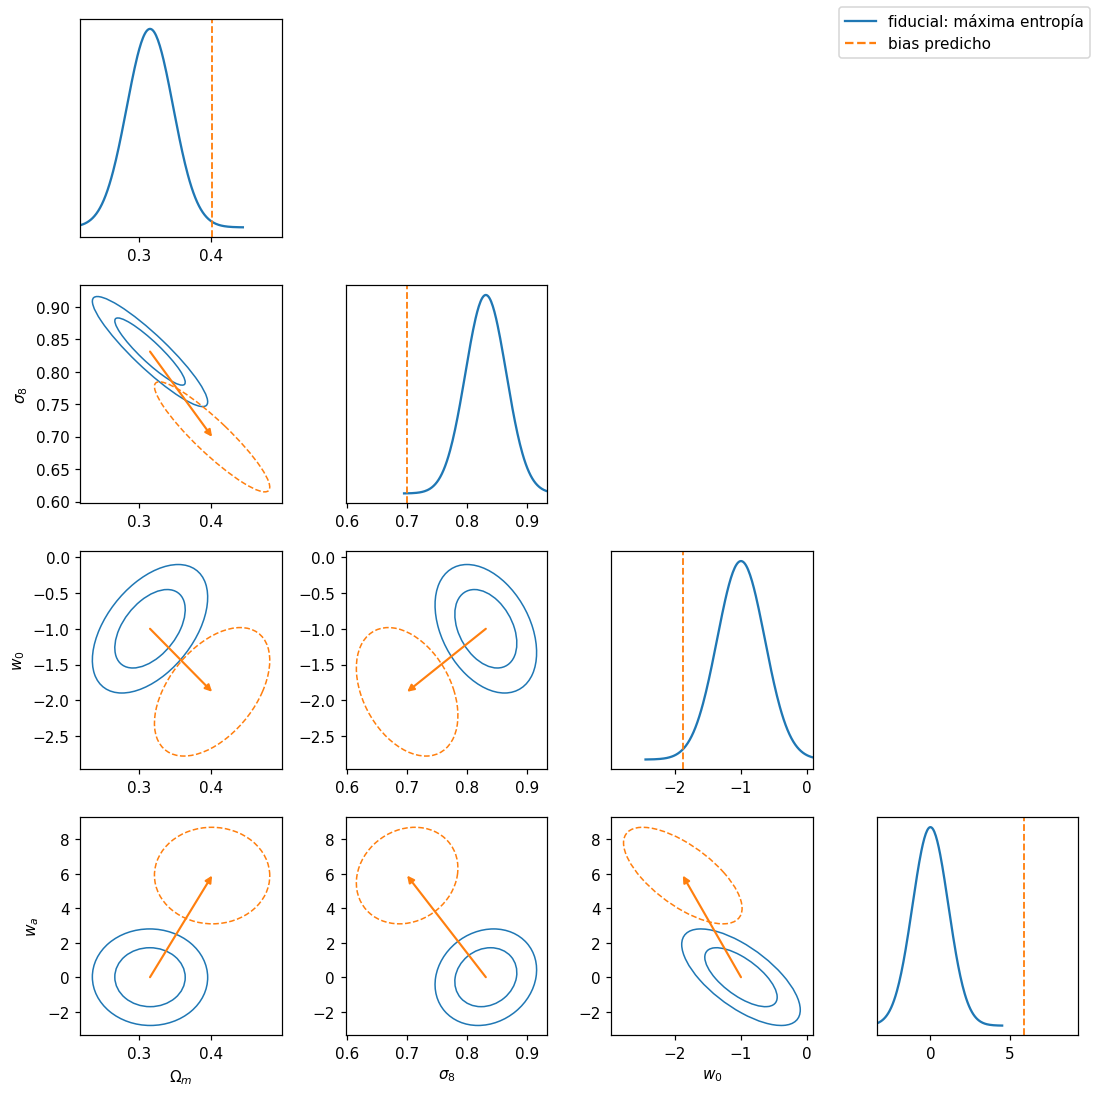

In [10]:
# Incluye ambos centros y sus contornos para no recortar las elipses desplazadas.
def limits_with_bias(parameter):
    centers = (res.param_fid[parameter], bias.shifted_fid(parameter))
    margin = 3.0 * res.sigma(parameter)
    return min(centers) - margin, max(centers) + margin

legend_handles = [
    Line2D([], [], color="C0", label="fiducial: máxima entropía"),
    Line2D([], [], color="C1", ls="--", label="bias predicho"),
]
fig = res.corner(COSMO_PARAMS, color="C0", label="máxima entropía", figsize=(10, 10))
bias.corner_arrows(COSMO_PARAMS, fig=fig, shifted_contour=True, color="C1")
axes = np.asarray(fig.axes).reshape(len(COSMO_PARAMS), len(COSMO_PARAMS))
for row, p_y in enumerate(COSMO_PARAMS):
    for col, p_x in enumerate(COSMO_PARAMS[:row + 1]):
        axes[row, col].set_xlim(limits_with_bias(p_x))
        if row != col:
            axes[row, col].set_ylim(limits_with_bias(p_y))
fig.legend(handles=legend_handles, loc="upper right", fontsize=10)
fig.savefig(OUTPUT_DIR / "corner_moments_bias.png", dpi=160, bbox_inches="tight")
plt.show()

## Contornos y flechas en los dos planos cosmológicos

Los contornos azules corresponden a las regiones conjuntas de 68.3% y
95.4%. Las flechas muestran el bias; el contorno naranja discontinuo
representa la región de 95.4% trasladada.

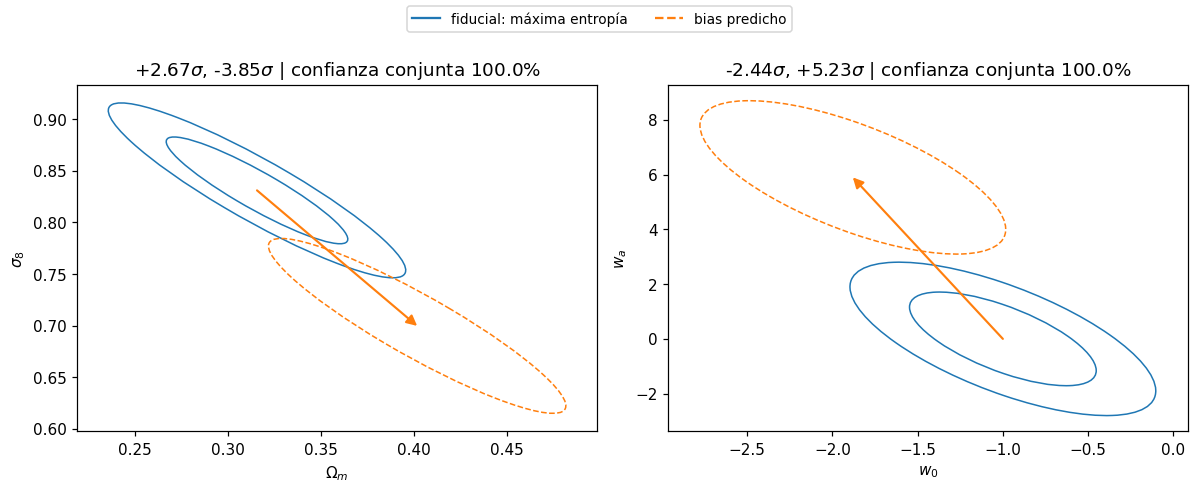

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (p1, p2) in zip(axes, PARAMETER_PAIRS):
    res.contour(p1, p2, ax=ax, color="C0")
    bias.arrow(p1, p2, ax=ax, shifted_contour=True, color="C1")
    joint = bias.bias_2d(p1, p2)
    ax.set_xlim(limits_with_bias(p1))
    ax.set_ylim(limits_with_bias(p2))
    ax.set_title(
        rf"{bias.n_sigma(p1):+.2f}$\sigma$, {bias.n_sigma(p2):+.2f}$\sigma$"
        f" | confianza conjunta {joint.confidence:.1%}"
    )
fig.legend(handles=legend_handles, loc="upper center", ncol=2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(OUTPUT_DIR / "contours_moments_bias.png", dpi=160, bbox_inches="tight")
plt.show()